# ML feature engineering — section 03 (steps 19–23, 18)

> **Development notebook.** Once final, converted to `util/ml_feature_engineering.py` and called from `script/mlpipeline.ipynb`. Change this notebook first, then re-convert.

Working order agreed: **19 → 23 → 18** (preprocessing is fitted on the final, filtered feature list). The split (step 17) is frozen in `datamart/gold/split/v1/`: anything that **learns or chooses** uses **train only**; fixed formulas are **applied to every partition**.

| Step | Decision | Reason |
|---|---|---|
| 19 Manual domain features | **Skipped — replaced by step 21** | OpenFE searches ratios / products / differences automatically; manual ratios are the fallback if OpenFE fails |
| 20 Temporal features | **Not applied** | Only clickstream varies over time; it is weak (max IV 0.09) and missing for 28% of loans (all after 2024-06) |
| **21 AutoFE (relational / tabular)** | **OpenFE on model-A features, train only** | After Gold the data is one flat row per loan → OpenFE (tabular interactions) fits; Featuretools (relational DFS) has no relational depth to use |
| 22 AutoFE time series | **Not applied** | Not a time-series problem |
| 23 Initial feature filtering | next | — |
| 18 Train-fitted preprocessing | after 23 | — |

In [1]:
import os, sys, time, json, warnings
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import yaml

PROJECT_DIR = os.environ.get("PROJECT_DIR") or ("/app" if os.path.isdir("/app/data") else os.path.abspath(".."))
sys.path.insert(0, PROJECT_DIR)
from util import dataprocessing_bronze as bronze
from util import dataprocessing_gold as gold          # feature store, split-aware loader, IV / AUC helpers

FE_VERSION = "v1"
FE_DIR = os.path.join(PROJECT_DIR, "datamart", "ml", "feature_engineering", FE_VERSION)
CHART_DIR = os.path.join(FE_DIR, "charts")
TMP_DIR = os.path.join(PROJECT_DIR, "datamart", "ml", "_tmp")
for d in (FE_DIR, CHART_DIR, TMP_DIR):
    os.makedirs(d, exist_ok=True)

spark = bronze.get_spark("ml_feature_engineering")
ctx = gold.load_eda_data(spark)          # all partitions (features) + train rows with labels (train only)
data, train = ctx["data"], ctx["train"]
assert set(train["partition"]) == {"train"}
print(f"Loans: {len(data):,} | train with labels: {len(train):,} | default rate {train['label'].mean():.2%}")

Loans: 12,500 | train with labels: 6,281 | default rate 28.86%


---

## Step 21 — AutoFE with OpenFE (train only)

**What OpenFE does:** generates candidate features from pairs of existing features, then ranks them in two stages by how much they improve a LightGBM model (on an internal split *inside train*), and returns the ranked list.

**Leakage-safe setup (our choices):**

| Setting | Value | Why |
|---|---|---|
| Base features | **Model A set (48, no clickstream)** | Champion model; clickstream is absent after 2024-06 |
| Rows | **train only** (6,281) | OpenFE uses the label to rank features |
| Operators | **row-wise only:** `+ − × ÷ min max` between two numeric features | OpenFE's group-by / frequency operators compute statistics over train **and test together** in its `transform()` — that would leak test data. Row-wise formulas need no statistics, so they are identical however the data is split |
| Order | 1 (pairs only) | Keeps formulas explainable (checklist: depth ≤ 2) |
| Kept | top **20** (`MAX_FEATURES`) after removing duplicates | Bounded, explainable candidate set; step 23 filters further |
| Application | our own pandas code (tested equal to OpenFE) | Inference later does not depend on OpenFE |

In [2]:
from openfe import OpenFE
from openfe.openfe import get_candidate_features, num_num_operators
from openfe.utils import tree_to_formula

MAX_FEATURES = 20                 # configurable bound on generated features kept
SEED = 42
N_JOBS = 4
DUPLICATE_RHO = 0.98              # |Spearman| at or above this with an existing / earlier feature = duplicate formula

BASE = ctx["features_a"]                                                     # 48 model-A features
NUMERIC_A = [c for c in ctx["numeric"] if c in BASE]                         # 18 numeric base features
CATEGORICAL_A = [c for c in ctx["categorical"] if c in BASE]

# Categories -> fixed integer codes from the Silver allowed sets (a fixed rule, nothing learned)
from util import dataprocessing_silver as silver
CAT_LEVELS = {c: lv for (t, c), lv in silver.VALID_CATEGORIES.items()}
def encode_for_openfe(df):
    out = df[BASE].copy()
    for c in CATEGORICAL_A:
        out[c] = pd.Categorical(out[c], categories=CAT_LEVELS[c]).codes.astype(float)
        out.loc[out[c] < 0, c] = np.nan
    return out.astype(float)

X_train = encode_for_openfe(train).reset_index(drop=True)
y_train = train[["label"]].reset_index(drop=True)

candidates = [f for f in get_candidate_features(numerical_features=NUMERIC_A, order=1) if f.name in num_num_operators]
gold.check_predictors(BASE)        # every input is allowed by the data contract -> generated features inherit it
print(f"Numeric base features: {len(NUMERIC_A)} | row-wise candidates: {len(candidates)} "
      f"(operators {sorted({f.name for f in candidates})})")

Numeric base features: 18 | row-wise candidates: 918 (operators ['*', '+', '-', '/', 'max', 'min'])


In [3]:
t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    ofe = OpenFE()
    ranked = ofe.fit(data=X_train, label=y_train, task="classification", candidate_features_list=candidates,
                     categorical_features=CATEGORICAL_A, n_jobs=N_JOBS, seed=SEED, verbose=False,
                     tmp_save_path=os.path.join(TMP_DIR, "openfe_tmp.feather"))
gen_seconds = time.time() - t0
print(f"OpenFE ranked {len(ranked)} candidate features in {gen_seconds:.0f} s")

  0%|          | 0/16 [00:00<?, ?it/s]

  6%|▋         | 1/16 [00:01<00:21,  1.46s/it]

 31%|███▏      | 5/16 [00:01<00:02,  3.72it/s]

 56%|█████▋    | 9/16 [00:01<00:01,  6.51it/s]

 81%|████████▏ | 13/16 [00:02<00:00,  8.79it/s]

...

  6%|▋         | 1/16 [00:01<00:18,  1.22s/it]

 44%|████▍     | 7/16 [00:01<00:01,  6.99it/s]

 81%|████████▏ | 13/16 [00:01<00:00, 13.38it/s]

100%|██████████| 16/16 [00:01<00:00, 10.85it/s]

OpenFE ranked 856 candidate features in 9 s


In [4]:
OP_NAME = {"+": "add", "-": "sub", "*": "mul", "/": "div", "min": "min", "max": "max"}

def describe(node):
    a, b = node.children[0].name, node.children[1].name
    return dict(operator=node.name, feature_1=a, feature_2=b, formula=tree_to_formula(node),
                name=f"afe_{OP_NAME[node.name]}__{a}__{b}")

def apply_formula(df, operator, a, b):
    # Row-wise, no fitted statistics: identical on every partition and at inference
    x, y = df[a].astype(float), df[b].astype(float)
    if operator == "+":   return x + y
    if operator == "-":   return x - y
    if operator == "*":   return x * y
    if operator == "/":   return x / y.replace(0, np.nan)          # zero denominator -> null
    if operator == "min": return np.minimum(x, y)
    if operator == "max": return np.maximum(x, y)
    raise ValueError(operator)

ranking = pd.DataFrame([dict(rank=i + 1, **describe(n)) for i, n in enumerate(ranked)])
ranking.to_csv(os.path.join(FE_DIR, "autofe_ranking_all.csv"), index=False)

# Test: our implementation reproduces OpenFE's own calculation on train
for n in ranked[:MAX_FEATURES * 2]:
    d = describe(n)
    ours = apply_formula(X_train, d["operator"], d["feature_1"], d["feature_2"])
    theirs = n.calculate(X_train)
    assert np.allclose(ours.fillna(-9e99), pd.Series(np.asarray(theirs, dtype=float)).fillna(-9e99)), d["formula"]
    n.delete()
print("Formula test passed: our row-wise implementation equals OpenFE's calculation for the top candidates")
ranking.head(10)

Formula test passed: our row-wise implementation equals OpenFE's calculation for the top candidates


,rank,operator,feature_1,feature_2,formula,name
0,1,*,Interest_Rate,Outstanding_Debt,(Interest_Rate*Outstanding_Debt),afe_mul__Interest_Rate__Outstanding_Debt
1,2,*,Num_Credit_Inquiries,Outstanding_Debt,(Num_Credit_Inquiries*Outstanding_Debt),afe_mul__Num_Credit_Inquiries__Outstanding_Debt
2,3,*,Changed_Credit_Limit,Outstanding_Debt,(Changed_Credit_Limit*Outstanding_Debt),afe_mul__Changed_Credit_Limit__Outstanding_Debt
3,4,-,Delay_from_due_date,Num_of_Delayed_Payment,(Delay_from_due_date-Num_of_Delayed_Payment),afe_sub__Delay_from_due_date__Num_of_Delayed_P...
4,5,*,Delay_from_due_date,Outstanding_Debt,(Delay_from_due_date*Outstanding_Debt),afe_mul__Delay_from_due_date__Outstanding_Debt
5,6,/,Total_EMI_per_month,num_loan_types,(Total_EMI_per_month/num_loan_types),afe_div__Total_EMI_per_month__num_loan_types
6,7,min,Num_Credit_Card,Outstanding_Debt,"min(Num_Credit_Card,Outstanding_Debt)",afe_min__Num_Credit_Card__Outstanding_Debt
7,8,/,Num_Credit_Card,Num_of_Delayed_Payment,(Num_Credit_Card/Num_of_Delayed_Payment),afe_div__Num_Credit_Card__Num_of_Delayed_Payment
8,9,/,Outstanding_Debt,credit_history_age_months,(Outstanding_Debt/credit_history_age_months),afe_div__Outstanding_Debt__credit_history_age_...
9,10,/,Num_of_Loan,Total_EMI_per_month,(Num_of_Loan/Total_EMI_per_month),afe_div__Num_of_Loan__Total_EMI_per_month


In [5]:
# Keep the top MAX_FEATURES, discarding duplicate formulas (near-identical to a base feature or an earlier pick)
kept, rows = [], []
base_numeric = X_train[[c for c in BASE if X_train[c].nunique() > 2]]
for _, r in ranking.iterrows():
    if len(kept) >= MAX_FEATURES:
        break
    v = apply_formula(X_train, r["operator"], r["feature_1"], r["feature_2"])
    reason = ""
    if v.nunique(dropna=True) <= 1:
        reason = "constant"
    else:
        rho_base = base_numeric.corrwith(v, method="spearman").abs()
        rho_kept = pd.Series({k: v.corr(apply_formula(X_train, *kept_ops[k]), method="spearman")
                              for k in kept}, dtype=float).abs() if kept else pd.Series(dtype=float)
        if rho_base.max() >= DUPLICATE_RHO:
            reason = f"duplicate of base feature {rho_base.idxmax()} (rho {rho_base.max():.3f})"
        elif len(rho_kept) and rho_kept.max() >= DUPLICATE_RHO:
            reason = f"duplicate of {rho_kept.idxmax()} (rho {rho_kept.max():.3f})"
    if not reason:
        kept.append(r["name"])
        kept_ops = {**(kept_ops if len(kept) > 1 else {}), r["name"]: (r["operator"], r["feature_1"], r["feature_2"])}
    rows.append(dict(**r, kept=not reason, discard_reason=reason))
screen = pd.DataFrame(rows)
print(f"Screened {len(screen)} ranked candidates -> kept {screen['kept'].sum()}, "
      f"discarded {(~screen['kept']).sum()} (duplicates / constant)")

Screened 23 ranked candidates -> kept 20, discarded 3 (duplicates / constant)


In [6]:
# Catalog of kept features with train-only strength (IV, univariate AUC) — same measures as step 14
y = train["label"].reset_index(drop=True)
catalog = screen[screen["kept"]].copy().reset_index(drop=True)
catalog.insert(0, "feature_id", [f"AFE-{i + 1:02d}" for i in range(len(catalog))])
iv, auc, nulls = [], [], []
for _, r in catalog.iterrows():
    v = apply_formula(X_train, r["operator"], r["feature_1"], r["feature_2"])
    iv.append(gold.woe_iv(v, y, "numeric")[1])
    auc.append(gold.univariate_auc(v, y, "numeric")[0])
    nulls.append(v.isna().mean() * 100)
catalog["iv_train"], catalog["auc_train"], catalog["null_pct_train"] = iv, auc, nulls
catalog["iv_best_input"] = [max(gold.woe_iv(train[a].reset_index(drop=True), y, "numeric")[1],
                                gold.woe_iv(train[b].reset_index(drop=True), y, "numeric")[1])
                            for a, b in zip(catalog["feature_1"], catalog["feature_2"])]
catalog["iv_gain_vs_inputs"] = catalog["iv_train"] - catalog["iv_best_input"]
catalog["version_added"] = FE_VERSION
catalog["zero_denominator"] = np.where(catalog["operator"] == "/", "null", "n/a")
catalog = catalog.drop(columns=["kept", "discard_reason"])
catalog.to_csv(os.path.join(FE_DIR, "autofe_catalog.csv"), index=False)
screen.to_csv(os.path.join(FE_DIR, "autofe_screening.csv"), index=False)
catalog[["feature_id", "rank", "formula", "iv_train", "auc_train", "iv_best_input", "iv_gain_vs_inputs",
         "null_pct_train"]].style.hide(axis="index").format(
    {"iv_train": "{:.3f}", "auc_train": "{:.3f}", "iv_best_input": "{:.3f}", "iv_gain_vs_inputs": "{:+.3f}",
     "null_pct_train": "{:.1f}%"})

feature_id,rank,formula,iv_train,auc_train,iv_best_input,iv_gain_vs_inputs,null_pct_train
AFE-01,1,(Interest_Rate*Outstanding_Debt),0.932,0.727,0.865,+0.067,2.0%
AFE-02,2,(Num_Credit_Inquiries*Outstanding_Debt),0.887,0.731,0.865,+0.022,1.4%
AFE-03,3,(Changed_Credit_Limit*Outstanding_Debt),0.403,0.657,0.865,-0.462,2.2%
AFE-04,4,(Delay_from_due_date-Num_of_Delayed_Payment),0.402,0.661,0.560,-0.158,1.6%
AFE-05,5,(Delay_from_due_date*Outstanding_Debt),0.833,0.734,0.865,-0.032,0.0%
AFE-06,6,(Total_EMI_per_month/num_loan_types),0.278,0.609,0.439,-0.162,14.6%
AFE-07,8,(Num_Credit_Card/Num_of_Delayed_Payment),0.062,0.522,0.455,-0.393,5.6%
AFE-08,9,(Outstanding_Debt/credit_history_age_months),0.864,0.726,0.865,-0.001,0.0%
AFE-09,11,(Num_Bank_Accounts-Delay_from_due_date),0.456,0.683,0.560,-0.104,1.1%
AFE-10,12,(Annual_Income/Total_EMI_per_month),0.285,0.604,0.231,+0.054,14.4%


### Apply the formulas to every partition (no fitting)

The generated features are fixed formulas, so they are computed for train, validation, test and OOT alike. Saved as the **candidate feature matrix** for step 23: `autofe_features.parquet` (`loan_id`, `partition`, the generated features).

In [7]:
X_all = encode_for_openfe(data)
gen = pd.DataFrame({r["name"]: apply_formula(X_all, r["operator"], r["feature_1"], r["feature_2"]).values
                    for _, r in catalog.iterrows()}, index=data.index)
matrix = pd.concat([data[["loan_id", "partition"]], gen], axis=1)
matrix.to_parquet(os.path.join(FE_DIR, "autofe_features.parquet"), index=False)

# Same values on train as during the search (applied, not refit)
tr = matrix[matrix["partition"] == "train"].set_index("loan_id").loc[train["loan_id"]]
for _, r in catalog.iterrows():
    ref = apply_formula(X_train, r["operator"], r["feature_1"], r["feature_2"])
    assert np.allclose(tr[r["name"]].fillna(-9e99).values, ref.fillna(-9e99).values)

null_by_part = matrix.groupby("partition")[list(gen.columns)].apply(lambda g: g.isna().mean() * 100).T
print(f"Candidate matrix: {matrix.shape[0]:,} loans x {gen.shape[1]} generated features | "
      f"max null % by partition: {null_by_part.max().round(2).to_dict()}")

config = dict(version=FE_VERSION, tool="openfe 0.0.12", base_feature_set="model A (no clickstream)",
              base_features=len(BASE), numeric_base_features=len(NUMERIC_A), operators=sorted(num_num_operators),
              order=1, candidates=len(candidates), ranked=len(ranked), max_features=MAX_FEATURES,
              kept=int(len(catalog)), duplicate_rho=DUPLICATE_RHO, seed=SEED, rows="train only",
              train_rows=int(len(train)), generation_seconds=round(gen_seconds, 1),
              created_ts=datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"))
with open(os.path.join(FE_DIR, "autofe_config.yaml"), "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False)
config

Candidate matrix: 12,500 loans x 20 generated features | max null % by partition: {'oot': 13.7, 'test': 15.29, 'train': 14.58, 'validation': 13.0}


{'version': 'v1',
 'tool': 'openfe 0.0.12',
 'base_feature_set': 'model A (no clickstream)',
 'base_features': 48,
 'numeric_base_features': 18,
 'operators': ['*', '+', '-', '/', 'max', 'min'],
 'order': 1,
 'candidates': 918,
 'ranked': 856,
 'max_features': 20,
 'kept': 20,
 'duplicate_rho': 0.98,
 'seed': 42,
 'rows': 'train only',
 'train_rows': 6281,
 'generation_seconds': 9.0,
 'created_ts': '2026-10-19T14:27:44Z'}

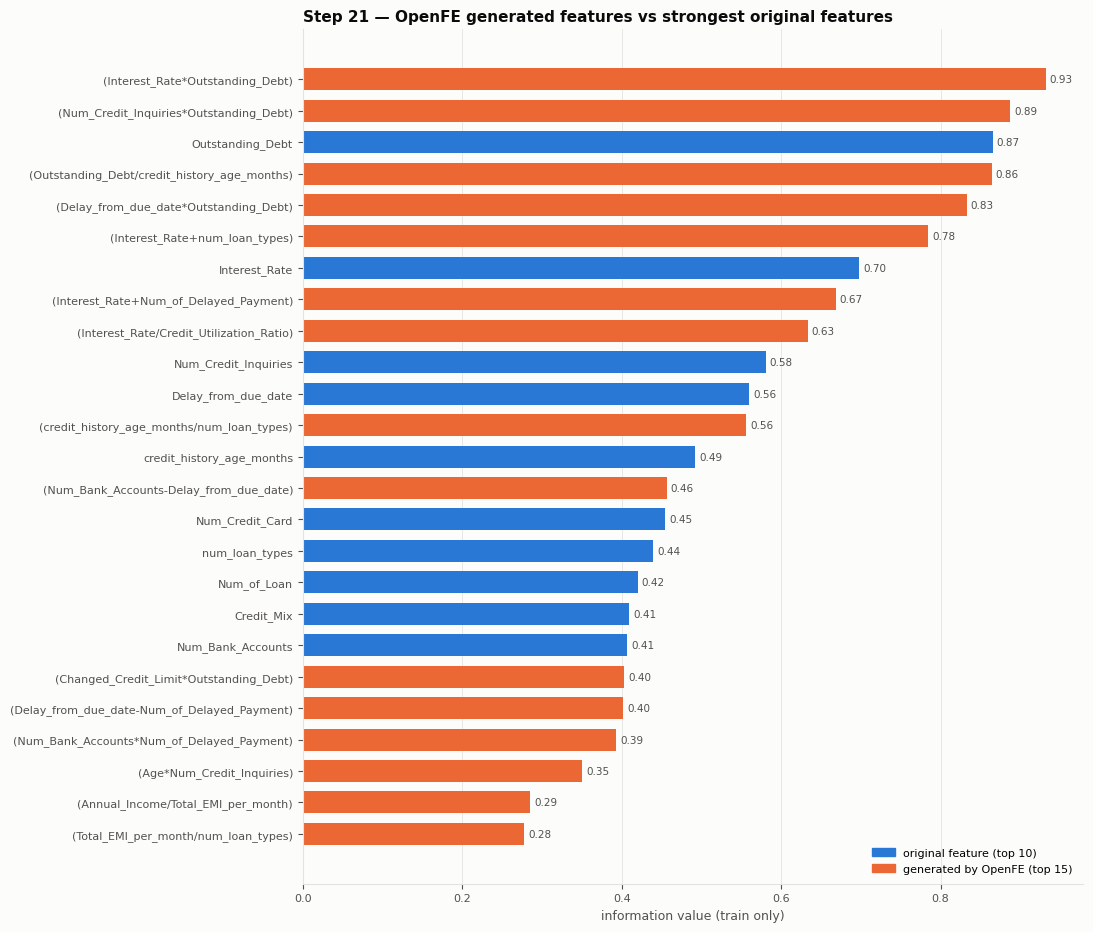

In [8]:
# Chart: generated features vs the strongest original features (train-only IV)
import matplotlib.pyplot as plt
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "xtick.color": INK_2, "ytick.color": INK_2,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "legend.fontsize": 8, "font.size": 9})

rel = pd.read_csv(os.path.join(gold.EDA_DIR, "feature_target_relationships.csv"))
orig = rel[rel["in_set_A"]].nlargest(10, "iv")[["feature", "iv"]].assign(kind="original")
genr = catalog.nlargest(15, "iv_train")[["formula", "iv_train"]].rename(columns={"formula": "feature", "iv_train": "iv"}).assign(kind="generated (OpenFE)")
both = pd.concat([orig, genr]).sort_values("iv")
fig, ax = plt.subplots(figsize=(11, 0.32 * len(both) + 1.4))
ax.barh(both["feature"], both["iv"], color=[SERIES[0] if k == "original" else SERIES[1] for k in both["kind"]], height=0.7)
for yv, v in enumerate(both["iv"]):
    ax.text(v + 0.005, yv, f"{v:.2f}", va="center", fontsize=7.5, color=INK_2)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in SERIES], ["original feature (top 10)", "generated by OpenFE (top 15)"],
          loc="lower right")
ax.set_xlabel("information value (train only)")
ax.grid(axis="y", visible=False)
ax.set_title("Step 21 — OpenFE generated features vs strongest original features")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "21_autofe_vs_original_iv.png"), dpi=130, bbox_inches="tight")
plt.show()

### Step 21 summary

- Candidates: row-wise pairs of the 18 numeric model-A features; ranked by OpenFE on **train only**; top 20 kept after removing duplicate / constant formulas.
- Outputs (`datamart/ml/feature_engineering/v1/`): `autofe_catalog.csv` (definition catalog: formula, inputs, operator, zero-denominator rule, train IV/AUC, gain over the best input), `autofe_ranking_all.csv`, `autofe_screening.csv`, `autofe_features.parquet` (candidate matrix, all partitions), `autofe_config.yaml` (settings + generation time), chart `21_autofe_vs_original_iv.png`.
- Whether these features actually help is **not** decided here: step 23 filters them on train, and steps 25/28 compare models with and without them against the **raw-only baseline**.

---

## Step 23 — Initial feature filtering (V6.6: train-only screens, flag rather than drop)

Candidate pool: **48 model-A base features + 20 generated (step 21) + 20 clickstream (model B only) = 88**. All screens use **train only**; the **validation** partition is used only to document the impact of the keep/drop decisions (test and OOT are never touched).

**Screens (each recorded as a flag):**

| Screen | Flag rule | Tool |
|---|---|---|
| Missingness | missing on train > 50% | pandas |
| Low variance | most common value ≥ 99.5% of train | pandas |
| Exact duplicate | identical values to another feature | pandas hash |
| Suspected leakage | univariate AUC on train > 0.85 | scikit-learn |
| Pairwise correlation | \|Spearman\| ≥ 0.95 (listed from 0.8) | pandas |
| Multicollinearity | **VIF** > 10 (reported for all numeric / 0-1 features) | statsmodels |
| Lag autocorrelation | **not applicable** — one row per loan, no time-ordered lags (recorded in the ACF report) | — |

**Model-specific keep / drop:**

| Model type | Dropped | Kept despite flags |
|---|---|---|
| **tree** (XGBoost, Random Forest) | only features with **no usable information**: low variance, exact duplicate, missing > 50%, suspected leakage | correlated / collinear features (trees are not harmed by them) |
| **linear** (logistic regression) | the tree drops **+** one of each near-duplicate pair (register preference → original over generated → higher IV) **+** iterative removal of the highest VIF until all ≤ 10 (generated features removed first) | — |

**Validation impact:** for every feature set × model type, a quick reference model (tree: `HistGradientBoostingClassifier`, linear: `LogisticRegression`) is trained on train **before** and **after** filtering and scored on validation (ROC-AUC, PR-AUC). This documents the effect; it is not model selection.

**Outputs:** `feature_filter_report.csv`, `filtered_features.json`, `correlation_report.csv`, `vif_report.csv`, `acf_report.csv`, `filter_validation_impact.csv`.

In [9]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

FILTER = dict(missing_pct_max=50.0, near_constant_share=0.995, leakage_auc=0.85,
              near_duplicate_rho=0.95, correlation_report_rho=0.8, vif_max=10.0)
PREFER_DROP = {"Num_of_Loan": "num_loan_types", "Annual_Income": "Monthly_Inhand_Salary"}   # from the step-16 register

afe = pd.read_parquet(os.path.join(FE_DIR, "autofe_features.parquet"))
AFE = list(catalog["name"])
CLICK = ctx["click"]
CAT = ctx["categorical"]
BINARY = ctx["binary"]
POOL = BASE + AFE + CLICK
SET_CANDIDATES = {"A_raw": BASE, "A_fe": BASE + AFE, "B_raw": BASE + CLICK, "B_fe": BASE + AFE + CLICK}

full = data.merge(afe.drop(columns="partition"), on="loan_id", how="left")
train_full = full[full["partition"] == "train"].merge(train[["loan_id", "label"]], on="loan_id")
assert len(train_full) == len(train)
y_tr = train_full["label"].reset_index(drop=True)

def origin(c):
    return "generated" if c in AFE else "clickstream" if c in CLICK else "original"

# --- per-feature screens (train only) ---
rows = []
for c in POOL:
    s = train_full[c].reset_index(drop=True)
    kind = "categorical" if c in CAT else "binary" if c in BINARY else "numeric"
    rows.append(dict(feature=c, origin=origin(c), kind=kind, missing_pct=s.isna().mean() * 100,
                     top_share=s.value_counts(normalize=True, dropna=False).iloc[0],
                     iv=gold.woe_iv(s, y_tr, kind)[1], auc=gold.univariate_auc(s, y_tr, kind)[0]))
report = pd.DataFrame(rows).set_index("feature")
report["flag_missing"] = report["missing_pct"] > FILTER["missing_pct_max"]
report["flag_low_variance"] = report["top_share"] >= FILTER["near_constant_share"]
report["flag_leakage"] = report["auc"].fillna(0) > FILTER["leakage_auc"]

hashes, dup_of = {}, {}
for c in POOL:
    key = pd.util.hash_pandas_object(train_full[c].astype(str), index=False).sum()
    if key in hashes:
        dup_of[c] = hashes[key]
    else:
        hashes[key] = c
report["exact_duplicate_of"] = pd.Series(dup_of)
report["flag_exact_duplicate"] = report["exact_duplicate_of"].notna()
print("Screens done:", {k: int(report[k].sum()) for k in ["flag_missing", "flag_low_variance", "flag_leakage",
                                                          "flag_exact_duplicate"]})

Screens done: {'flag_missing': 0, 'flag_low_variance': 2, 'flag_leakage': 0, 'flag_exact_duplicate': 0}


In [10]:
# --- pairwise correlation report (train, Spearman, numeric + 0/1 features) ---
num_like = [c for c in POOL if c not in CAT and train_full[c].nunique() > 1]
rho = train_full[num_like].corr(method="spearman")
pairs = (rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack().rename("spearman").reset_index()
         .rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
pairs["abs_rho"] = pairs["spearman"].abs()
corr_report = pairs[pairs["abs_rho"] >= FILTER["correlation_report_rho"]].sort_values("abs_rho", ascending=False)
corr_report = corr_report.assign(origin_1=corr_report["feature_1"].map(origin), origin_2=corr_report["feature_2"].map(origin),
                                 near_duplicate=corr_report["abs_rho"] >= FILTER["near_duplicate_rho"])
corr_report.to_csv(os.path.join(FE_DIR, "correlation_report.csv"), index=False)
max_corr = pairs.assign(a=pairs["feature_1"], b=pairs["feature_2"])
partner = pd.concat([max_corr[["a", "b", "abs_rho"]], max_corr.rename(columns={"a": "b", "b": "a"})[["a", "b", "abs_rho"]]])
best = partner.sort_values("abs_rho", ascending=False).drop_duplicates("a").set_index("a")
report["max_abs_rho"] = best["abs_rho"]
report["max_rho_partner"] = best["b"]
report["flag_near_duplicate"] = report["max_abs_rho"].fillna(0) >= FILTER["near_duplicate_rho"]

# --- ACF report: not applicable (recorded) ---
acf_report = pd.DataFrame([dict(scope="all features", applicable=False,
                                reason="one row per loan scored at loan_start_date; features are as-of snapshots, "
                                       "not ordered series per entity, so lag autocorrelation is undefined",
                                action="none")])
acf_report.to_csv(os.path.join(FE_DIR, "acf_report.csv"), index=False)
print(f"Correlation report: {len(corr_report)} pairs with |rho| >= {FILTER['correlation_report_rho']} "
      f"({int(corr_report['near_duplicate'].sum())} near-duplicates >= {FILTER['near_duplicate_rho']})")

Correlation report: 43 pairs with |rho| >= 0.8 (7 near-duplicates >= 0.95)


In [11]:
# --- VIF (train, statsmodels) on median-imputed, standardised numeric + 0/1 features ---
def vif_table(features):
    X = train_full[features].astype(float)
    X = X.fillna(X.median())
    X = X.loc[:, X.std() > 0]
    X = (X - X.mean()) / X.std()
    Xc = np.column_stack([np.ones(len(X)), X.values])
    return pd.Series([variance_inflation_factor(Xc, i + 1) for i in range(X.shape[1])], index=X.columns)

def vif_prune(features):
    # Remove the highest VIF > limit one at a time (generated features first), recording the order
    feats, removed = list(features), []
    while True:
        v = vif_table(feats)
        high = v[v > FILTER["vif_max"]]
        if high.empty:
            return feats, removed, v
        gen_high = high[[c for c in high.index if origin(c) == "generated"]]
        worst = (gen_high if not gen_high.empty else high).idxmax()
        removed.append((worst, float(high[worst])))
        feats.remove(worst)

screen_drop = report.index[report[["flag_missing", "flag_low_variance", "flag_leakage", "flag_exact_duplicate"]].any(axis=1)]
vif_all = vif_table([c for c in num_like if c not in screen_drop])
vif_report = vif_all.rename("vif_all_candidates").to_frame()
vif_report["origin"] = vif_report.index.map(origin)
vif_report["flag_vif_gt_10"] = vif_report["vif_all_candidates"] > FILTER["vif_max"]
report["vif"] = vif_report["vif_all_candidates"]
report["flag_high_vif"] = report["vif"].fillna(0) > FILTER["vif_max"]
print(f"VIF > {FILTER['vif_max']:.0f} among all candidates: {int(vif_report['flag_vif_gt_10'].sum())} features "
      f"(max {vif_all.max():,.0f})")

VIF > 10 among all candidates: 21 features (max 1,264)


In [12]:
# --- model-specific keep / drop per feature set ---
def near_duplicate_drops(features):
    drops = {}
    fs_pairs = corr_report[corr_report["near_duplicate"] & corr_report["feature_1"].isin(features)
                           & corr_report["feature_2"].isin(features)]
    for _, p in fs_pairs.iterrows():
        a, b = p["feature_1"], p["feature_2"]
        if a in drops or b in drops:
            continue
        if a in PREFER_DROP or b in PREFER_DROP:
            loser = a if a in PREFER_DROP else b
        elif origin(a) != origin(b) and "generated" in (origin(a), origin(b)):
            loser = a if origin(a) == "generated" else b
        else:
            loser = a if report.at[a, "iv"] < report.at[b, "iv"] else b
        drops[loser] = f"near-duplicate of {b if loser == a else a} (|rho| {p['abs_rho']:.3f})"
    return drops

filtered, decisions, vif_steps = {}, [], []
for set_name, cands in SET_CANDIDATES.items():
    common = {c: reason for c in cands for reason in [
        "low variance" if report.at[c, "flag_low_variance"] else
        f"exact duplicate of {report.at[c, 'exact_duplicate_of']}" if report.at[c, "flag_exact_duplicate"] else
        "missing > 50%" if report.at[c, "flag_missing"] else
        "suspected leakage" if report.at[c, "flag_leakage"] else ""] if reason}
    tree_keep = [c for c in cands if c not in common]
    nd = near_duplicate_drops(tree_keep)
    lin_after_nd = [c for c in tree_keep if c not in nd]
    lin_num = [c for c in lin_after_nd if c not in CAT and train_full[c].nunique() > 1]
    kept_num, vif_removed, final_vif = vif_prune(lin_num)
    vif_drop = {c: f"VIF {v:,.1f} > {FILTER['vif_max']:.0f} (iterative removal)" for c, v in vif_removed}
    lin_keep = [c for c in lin_after_nd if c not in vif_drop]
    filtered[set_name] = {"tree": tree_keep, "linear": lin_keep}
    for i, (c, v) in enumerate(vif_removed, 1):
        vif_steps.append(dict(feature_set=set_name, order=i, removed=c, vif_at_removal=v, origin=origin(c)))
    for c in cands:
        decisions.append(dict(feature_set=set_name, feature=c, origin=origin(c),
                              tree="drop" if c in common else "keep",
                              linear="drop" if (c in common or c in nd or c in vif_drop) else "keep",
                              reason=common.get(c) or nd.get(c) or vif_drop.get(c) or "",
                              final_linear_vif=float(final_vif.get(c, np.nan))))

decisions = pd.DataFrame(decisions)
pd.DataFrame(vif_steps).to_csv(os.path.join(FE_DIR, "vif_removal_steps.csv"), index=False)
vif_report.reset_index().rename(columns={"index": "feature"}).to_csv(os.path.join(FE_DIR, "vif_report.csv"), index=False)
for set_name in filtered:
    assert not set(filtered["A_raw"]["tree"]) & set(AFE + CLICK)        # raw-only baseline stays original-only
print({s: {m: len(v) for m, v in d.items()} for s, d in filtered.items()})

{'A_raw': {'tree': 46, 'linear': 43}, 'A_fe': {'tree': 66, 'linear': 51}, 'B_raw': {'tree': 66, 'linear': 63}, 'B_fe': {'tree': 86, 'linear': 71}}


### Validation impact of the keep / drop decisions

Reference models with fixed settings, trained on **train**, scored on **validation** only. Purpose: show the filtering does not throw away useful signal (or show what it costs). Validation labels are loaded explicitly for this; test and OOT labels are not read.

In [13]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import OneHotEncoder, QuantileTransformer

FLAGGED = {c[: -len("_invalid")] for c in BASE if c.endswith("_invalid")}

def build_preprocessor(features, model_type):
    cat = [c for c in features if c in CAT]
    binary = [c for c in features if c in BINARY]
    num = [c for c in features if c not in cat + binary]
    num_flagged = [c for c in num if c in FLAGGED]
    num_other = [c for c in num if c not in FLAGGED]

    def num_pipe():
        steps = [("impute", SimpleImputer(strategy="median"))]
        if model_type == "linear":
            steps.append(("quantile", QuantileTransformer(n_quantiles=1000, output_distribution="normal",
                                                          random_state=SEED)))
        return Pipeline(steps)

    parts = [("num_flagged", num_pipe(), num_flagged),
             ("num_other", num_pipe(), num_other),
             ("missing_ind", MissingIndicator(features="missing-only", error_on_new=False), num_other),
             ("cat", Pipeline([("fill", SimpleImputer(strategy="constant", fill_value="Missing")),
                               ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat),
             ("flags", SimpleImputer(strategy="constant", fill_value=0), binary)]
    return ColumnTransformer([p for p in parts if p[2]], remainder="drop", verbose_feature_names_out=True)

def reference_model(model_type):
    if model_type == "tree":
        return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=SEED)
    return LogisticRegression(max_iter=3000, C=1.0)

val_labels = (spark.read.parquet(gold.LABEL_STORE_PATH).filter("maturity_status = 'mature'")
              .select("loan_id", "label").toPandas())
val_full = full[full["partition"] == "validation"].merge(val_labels, on="loan_id")
assert set(val_full["partition"]) == {"validation"}

impact = []
for set_name, cands in SET_CANDIDATES.items():
    for model_type in ["tree", "linear"]:
        for stage, feats in [("before filtering", cands), ("after filtering", filtered[set_name][model_type])]:
            pipe = Pipeline([("pre", build_preprocessor(feats, model_type)), ("model", reference_model(model_type))])
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                pipe.fit(train_full[feats], train_full["label"])
            p = pipe.predict_proba(val_full[feats])[:, 1]
            impact.append(dict(feature_set=set_name, model_type=model_type, stage=stage, features=len(feats),
                               val_roc_auc=roc_auc_score(val_full["label"], p),
                               val_pr_auc=average_precision_score(val_full["label"], p)))
impact = pd.DataFrame(impact)
wide = impact.pivot_table(index=["feature_set", "model_type"], columns="stage",
                          values=["features", "val_roc_auc", "val_pr_auc"]).reset_index()
wide.columns = [" ".join(c).strip() for c in wide.columns]
wide["delta_roc_auc"] = wide["val_roc_auc after filtering"] - wide["val_roc_auc before filtering"]
wide["delta_pr_auc"] = wide["val_pr_auc after filtering"] - wide["val_pr_auc before filtering"]
wide.to_csv(os.path.join(FE_DIR, "filter_validation_impact.csv"), index=False)
wide.style.hide(axis="index").format({c: "{:.4f}" for c in wide.columns if "auc" in c} |
                                     {c: "{:.0f}" for c in wide.columns if c.startswith("features")})

feature_set,model_type,features after filtering,features before filtering,val_pr_auc after filtering,val_pr_auc before filtering,val_roc_auc after filtering,val_roc_auc before filtering,delta_roc_auc,delta_pr_auc
A_fe,linear,51,68,0.5844,0.6158,0.7628,0.7745,-0.0116,-0.0314
A_fe,tree,66,68,0.6051,0.6051,0.7894,0.7894,0.0000,0.0000
A_raw,linear,43,48,0.5772,0.5810,0.7603,0.7610,-0.0006,-0.0037
A_raw,tree,46,48,0.6257,0.6257,0.8074,0.8074,0.0000,0.0000
B_fe,linear,71,88,0.6017,0.6250,0.7741,0.7847,-0.0106,-0.0232
B_fe,tree,86,88,0.6404,0.6404,0.8089,0.8089,0.0000,0.0000
B_raw,linear,63,68,0.5962,0.5963,0.7716,0.7726,-0.0010,-0.0001
B_raw,tree,66,68,0.6510,0.6510,0.8189,0.8189,0.0000,0.0000


In [14]:
# --- final report + filtered_features.json ---
dec_wide = decisions.pivot_table(index="feature", columns="feature_set", values="linear", aggfunc="first")
report["tree_decision"] = np.where(report[["flag_missing", "flag_low_variance", "flag_leakage",
                                           "flag_exact_duplicate"]].any(axis=1), "drop", "keep")
lin_any = decisions.groupby("feature").apply(lambda g: "drop" if (g["linear"] == "drop").all() else
                                             ("keep" if (g["linear"] == "keep").all() else "depends on set"),
                                             include_groups=False)
report["linear_decision"] = lin_any
first_reason = decisions[decisions["reason"] != ""].drop_duplicates("feature").set_index("feature")["reason"]
report["reason"] = first_reason
report = report.reset_index()
report.to_csv(os.path.join(FE_DIR, "feature_filter_report.csv"), index=False)
decisions.to_csv(os.path.join(FE_DIR, "feature_filter_decisions_by_set.csv"), index=False)

with open(os.path.join(FE_DIR, "filtered_features.json"), "w", encoding="utf-8") as f:
    json.dump({"version": FE_VERSION, "filters": FILTER, "baseline_set": "A_raw",
               "sets": filtered}, f, indent=1)
# keep the step-18 / modelling interface: feature_sets.yaml mirrors filtered_features.json
with open(os.path.join(FE_DIR, "feature_sets.yaml"), "w", encoding="utf-8") as f:
    yaml.safe_dump({"version": FE_VERSION, "filters": FILTER, "sets": filtered}, f, sort_keys=False)

flag_cols = ["flag_missing", "flag_low_variance", "flag_leakage", "flag_exact_duplicate", "flag_near_duplicate", "flag_high_vif"]
print("Flags raised (88 candidates):", {c.replace("flag_", ""): int(report[c].sum()) for c in flag_cols})
print("Tree decision:", report["tree_decision"].value_counts().to_dict(),
      "| Linear decision:", report["linear_decision"].value_counts().to_dict())
report[report[flag_cols].any(axis=1)][["feature", "origin", "vif", "max_abs_rho", "max_rho_partner", "tree_decision",
                                       "linear_decision", "reason"]].style.hide(axis="index").format(
    {"vif": "{:,.1f}", "max_abs_rho": "{:.3f}"}, na_rep="")

Flags raised (88 candidates): {'missing': 0, 'low_variance': 2, 'leakage': 0, 'exact_duplicate': 0, 'near_duplicate': 11, 'high_vif': 21}
Tree decision: {'keep': 86, 'drop': 2} | Linear decision: {'keep': 71, 'drop': 16, 'depends on set': 1}


feature,origin,vif,max_abs_rho,max_rho_partner,tree_decision,linear_decision,reason
Annual_Income,original,28.0,0.994,Monthly_Inhand_Salary,keep,drop,near-duplicate of Monthly_Inhand_Salary (|rho| 0.994)
Monthly_Inhand_Salary,original,32.2,0.994,Annual_Income,keep,keep,
Interest_Rate,original,876.4,0.978,afe_add__Interest_Rate__num_loan_types,keep,keep,
Num_of_Loan,original,11.8,1.000,num_loan_types,keep,drop,near-duplicate of num_loan_types (|rho| 1.000)
Delay_from_due_date,original,217.3,0.977,afe_sub__Num_Bank_Accounts__Delay_from_due_date,keep,keep,
Num_of_Delayed_Payment,original,76.6,0.879,afe_mul__Num_Bank_Accounts__Num_of_Delayed_Payment,keep,keep,
Num_Credit_Inquiries,original,14.8,0.853,afe_mul__Age__Num_Credit_Inquiries,keep,depends on set,VIF 10.3 > 10 (iterative removal)
Outstanding_Debt,original,15.5,0.955,afe_div__Outstanding_Debt__credit_history_age_months,keep,keep,
Total_EMI_per_month,original,25.7,0.924,afe_div__Total_EMI_per_month__Monthly_Balance,keep,keep,
Amount_invested_monthly,original,21.2,0.662,afe_sub__Total_EMI_per_month__Amount_invested_monthly,keep,keep,


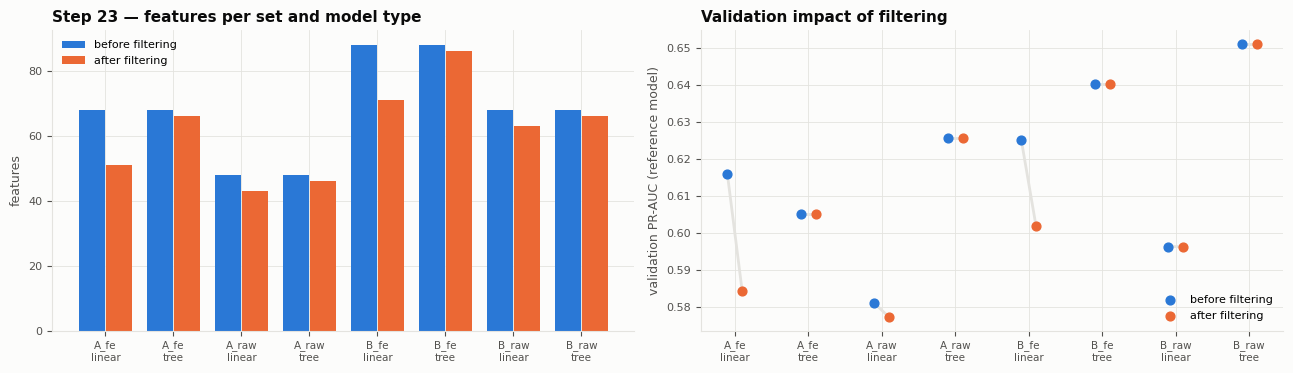

In [15]:
# Chart: features kept per feature set and model type, with validation PR-AUC before -> after
plt = __import__("matplotlib.pyplot").pyplot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
lab = [f"{r['feature_set']}\n{r['model_type']}" for _, r in wide.iterrows()]
x = np.arange(len(wide))
ax1.bar(x - 0.2, wide["features before filtering"], width=0.38, color=SERIES[0], label="before filtering")
ax1.bar(x + 0.2, wide["features after filtering"], width=0.38, color=SERIES[1], label="after filtering")
ax1.set_xticks(x, lab, fontsize=7.5)
ax1.set_ylabel("features")
ax1.legend(loc="upper left")
ax1.set_title("Step 23 — features per set and model type")
ax2.scatter(x - 0.1, wide["val_pr_auc before filtering"], color=SERIES[0], s=40, label="before filtering", zorder=3)
ax2.scatter(x + 0.1, wide["val_pr_auc after filtering"], color=SERIES[1], s=40, label="after filtering", zorder=3)
for xi, (b, a) in enumerate(zip(wide["val_pr_auc before filtering"], wide["val_pr_auc after filtering"])):
    ax2.plot([xi - 0.1, xi + 0.1], [b, a], color=GRID, linewidth=2, zorder=2)
ax2.set_xticks(x, lab, fontsize=7.5)
ax2.set_ylabel("validation PR-AUC (reference model)")
ax2.legend(loc="lower right")
ax2.set_title("Validation impact of filtering")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "23_feature_filtering.png"), dpi=130, bbox_inches="tight")
plt.show()

---

## Step 18 — Train-fitted preprocessing (refitted on the step-23 lists)

Built with scikit-learn (`ColumnTransformer` / `Pipeline`), **fitted on train only**, then only `transform` is applied to validation, test, OOT and (later) inference. One preprocessor per **feature set × model type**, using that model type's filtered list:

| Column type | `tree` variant (XGBoost, Random Forest) | `linear` variant (logistic regression) |
|---|---|---|
| Numeric with an `_invalid` flag | median imputation (the flag already marks missing) | + quantile transform to a normal shape (train quantiles) |
| Other numeric (incl. generated, clickstream) | median imputation + **missing indicator** (only for features missing in train) | + quantile transform |
| Categorical | `"Missing"` as its own category + one-hot; **unseen categories → all zeros** | same |
| 0/1 flags | passthrough (0 if ever missing) | same |

**Tests** (checklist): fitted on train only · validation / test / OOT never refit · unseen categories handled · a missing value in a column never missing in train is handled · no nulls in the output · same columns in every partition · deterministic.

In [16]:
import copy, joblib

PREP_DIR = os.path.join(PROJECT_DIR, "datamart", "ml", "preprocessing", FE_VERSION)
os.makedirs(PREP_DIR, exist_ok=True)
for f_old in os.listdir(PREP_DIR):                      # previous preprocessors are replaced
    os.remove(os.path.join(PREP_DIR, f_old))

part = {p: full[full["partition"] == p] for p in ["train", "validation", "test", "oot"]}
fitted, manifest_rows = {}, []
for set_name, by_type in filtered.items():
    for model_type in ["tree", "linear"]:
        feats = by_type[model_type]
        pre = build_preprocessor(feats, model_type).fit(part["train"][feats])
        fitted[(set_name, model_type)] = pre
        path = os.path.join(PREP_DIR, f"preprocess__{set_name}__{model_type}.joblib")
        joblib.dump(pre, path)
        out_names = list(pre.get_feature_names_out())
        manifest_rows.append(dict(feature_set=set_name, model_type=model_type, input_features=len(feats),
                                  output_columns=len(out_names), file=os.path.basename(path)))
        with open(path.replace(".joblib", "__columns.json"), "w", encoding="utf-8") as f:
            json.dump({"input": feats, "output": out_names}, f, indent=1)
prep_manifest = pd.DataFrame(manifest_rows)
prep_manifest.to_csv(os.path.join(PREP_DIR, "preprocessing_manifest.csv"), index=False)
prep_manifest.style.hide(axis="index")

feature_set,model_type,input_features,output_columns,file
A_raw,tree,46,72,preprocess__A_raw__tree.joblib
A_raw,linear,43,69,preprocess__A_raw__linear.joblib
A_fe,tree,66,110,preprocess__A_fe__tree.joblib
A_fe,linear,51,86,preprocess__A_fe__linear.joblib
B_raw,tree,66,92,preprocess__B_raw__tree.joblib
B_raw,linear,63,89,preprocess__B_raw__linear.joblib
B_fe,tree,86,130,preprocess__B_fe__tree.joblib
B_fe,linear,71,106,preprocess__B_fe__linear.joblib


### Step 18 tests — fit / transform

In [17]:
results = []
for (set_name, model_type), pre in fitted.items():
    feats = filtered[set_name][model_type]
    tr = part["train"][feats]
    names = [n for n, *_ in pre.transformers_]

    # 1. fitted on train only: imputation medians = train medians
    if "num_flagged" in names:
        cols = pre.transformers_[names.index("num_flagged")][2]
        assert np.allclose(pre.named_transformers_["num_flagged"].named_steps["impute"].statistics_,
                           tr[cols].median().values), "not train medians"

    # 2. transforming other partitions never refits
    before = copy.deepcopy(pre)
    outs = {p: pre.transform(part[p][feats]) for p in ["train", "validation", "test", "oot"]}
    for (n1, t1, _), (n2, t2, _) in zip(before.transformers_, pre.transformers_):
        objs = [(t1, t2)] + ([(s1, s2) for (_, s1), (_, s2) in zip(t1.steps, t2.steps)] if hasattr(t1, "steps") else [])
        for o1, o2 in objs:
            for attr in ["statistics_", "quantiles_", "categories_", "features_"]:
                if hasattr(o1, attr):
                    v1, v2 = getattr(o1, attr), getattr(o2, attr)
                    same = (all(np.array_equal(a, b) for a, b in zip(v1, v2)) if isinstance(v1, list)
                            else np.array_equal(v1, v2))
                    assert same, f"{set_name}/{model_type}: {n1}.{attr} changed after transform"

    # 3. + 4. unseen categories and a missing value where train had none
    probe = tr.iloc[[0, 1]].copy()
    for c in [c for c in feats if c in CAT]:
        probe[c] = ["Astronaut_NEW", None]
    for c in [c for c in feats if c not in CAT]:
        probe.iloc[1, probe.columns.get_loc(c)] = np.nan
    p_out = pre.transform(probe)

    # 5. no nulls, same width everywhere; 6. deterministic
    widths = {p: o.shape[1] for p, o in outs.items()}
    no_null = all(not np.isnan(np.asarray(o, dtype=float)).any() for o in list(outs.values()) + [p_out])
    deterministic = np.allclose(np.asarray(pre.transform(part["validation"][feats]), dtype=float),
                                np.asarray(outs["validation"], dtype=float), equal_nan=True)
    assert no_null and len(set(widths.values())) == 1 and deterministic
    results.append(dict(feature_set=set_name, model_type=model_type, columns=widths["train"], fitted_on="train",
                        no_refit=True, unseen_category_ok=True, new_missing_ok=True, no_nulls=no_null,
                        deterministic=deterministic))
print("Step 18 tests passed for all", len(results), "fitted preprocessors")
pd.DataFrame(results).style.hide(axis="index")

Step 18 tests passed for all 8 fitted preprocessors


feature_set,model_type,columns,fitted_on,no_refit,unseen_category_ok,new_missing_ok,no_nulls,deterministic
A_raw,tree,72,train,True,True,True,True,True
A_raw,linear,69,train,True,True,True,True,True
A_fe,tree,110,train,True,True,True,True,True
A_fe,linear,86,train,True,True,True,True,True
B_raw,tree,92,train,True,True,True,True,True
B_raw,linear,89,train,True,True,True,True,True
B_fe,tree,130,train,True,True,True,True,True
B_fe,linear,106,train,True,True,True,True,True


### Section 03 summary

- **21:** 20 OpenFE features (row-wise, train-only search) — catalog + candidate matrix.
- **23 (V6.6):** every screen recorded as a flag (missing, low variance, exact duplicate, leakage, correlation, **VIF**; ACF not applicable); **model-specific** keep/drop — tree models keep correlated features, linear models drop near-duplicates and high-VIF features; validation impact documented; `filtered_features.json` with the **raw-only baseline** `A_raw`.
- **18:** 8 preprocessors (4 feature sets × tree / linear, each on its own filtered list) in `datamart/ml/preprocessing/v1/`, all fit/transform tests passed. Inference = apply the step-21 formulas → `preprocessor.transform`.